<a href="https://practicalai.me"><img src="https://raw.githubusercontent.com/practicalAI/images/master/images/rounded_logo.png" width="100" align="left" hspace="20px" vspace="20px"></a>

<img src="https://raw.githubusercontent.com/practicalAI/images/master/basic_ml/08_Utilities/tensorboard.png" width="175" vspace="10px" align="right">

<div align="left">
<h1>Utilities</h1>

In this lesson, we will explore useful utilities in TensorFlow + Keras like [Generators](https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/data/Dataset), [Callbacks](https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/callbacks), [TensorBoard](https://www.tensorflow.org/guide/summaries_and_tensorboard) and [GradientTape](https://www.tensorflow.org/api_docs/python/tf/GradientTape).

<table align="center">
  <td>
<img src="https://raw.githubusercontent.com/practicalAI/images/master/images/rounded_logo.png" width="25"><a target="_blank" href="https://practicalai.me"> View on practicalAI</a>
  </td>
  <td>
<img src="https://raw.githubusercontent.com/practicalAI/images/master/images/colab_logo.png" width="25"><a target="_blank" href="https://colab.research.google.com/github/practicalAI/practicalAI/blob/master/notebooks/08_Utilities.ipynb"> Run in Google Colab</a>
  </td>
  <td>
<img src="https://raw.githubusercontent.com/practicalAI/images/master/images/github_logo.png" width="22"><a target="_blank" href="https://github.com/practicalAI/practicalAI/blob/master/notebooks/basic_ml/08_Utilities.ipynb"> View code on GitHub</a>
  </td>
</table>

# Overview

* **Generators**: generate batches of processed data
* **Callbacks:** Utility functions that are called at specific points during training/evaluation/inference. Checkout the [official documentation](https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/callbacks) for more information.
* **TensorBoard:** platform to visualize metrics, weights, gradients, model architecture, hyperparameter optimization, etc.
* **GradientTape:** class that allows us to define operations for a highly customized training loop.

# Set up

In [1]:
# Use TensorFlow 2.x
%tensorflow_version 2.x

TensorFlow 2.x selected.


In [0]:
import os
import numpy as np
import tensorflow as tf

In [0]:
# Arguments
SEED = 1234
DATA_FILE = "spiral.csv"
SHUFFLE = True
MODEL_FILE = 'model.hdf5'
INPUT_DIM = 2
NUM_CLASSES = 3
TRAIN_SIZE = 0.7
VAL_SIZE = 0.15
TEST_SIZE = 0.15
NUM_EPOCHS = 10
BATCH_SIZE = 32
HIDDEN_DIM = 100
DROPOUT_P = 0.1
LEARNING_RATE = 1e-2
EARLY_STOPPING_CRITERIA = 3 # deteriorating epochs

In [0]:
# Set seed for reproducability
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Data

Download non-linear spiral data for a classification task.

In [0]:
import matplotlib.pyplot as plt
import pandas as pd
import urllib

In [0]:
# Upload data from GitHub to notebook's local drive
url = "https://raw.githubusercontent.com/practicalAI/practicalAI/master/data/spiral.csv"
response = urllib.request.urlopen(url)
html = response.read()
with open(DATA_FILE, 'wb') as fp:
    fp.write(html)

In [7]:
# Load data
df = pd.read_csv(DATA_FILE, header=0)
X = df[['X1', 'X2']].values
y = df['color'].values
df.head(5)

,X1,X2,color
0,0.000000,0.000000,c1
1,-0.000457,0.001951,c1
2,0.001194,0.003826,c1
3,-0.000231,0.006008,c1
4,-0.000896,0.007966,c1


In [8]:
print ("X: ", np.shape(X))
print ("y: ", np.shape(y))

X:  (1500, 2)
y:  (1500,)


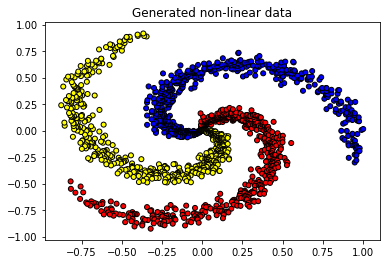

In [9]:
# Visualize data
plt.title("Generated non-linear data")
colors = {'c1': 'red', 'c2': 'yellow', 'c3': 'blue'}
plt.scatter(X[:, 0], X[:, 1], c=[colors[_y] for _y in y], edgecolors='k', s=25)
plt.show()

# Split data

In [0]:
import collections
import json
from sklearn.model_selection import train_test_split

### Components

In [0]:
def train_val_test_split(X, y, val_size, test_size, shuffle):
    """Split data into train/val/test datasets.
    """
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, shuffle=shuffle)
    X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=val_size, stratify=y_train, shuffle=shuffle)
    return X_train, X_val, X_test, y_train, y_val, y_test

### Operations

In [12]:
# Create data splits
X_train, X_val, X_test, y_train, y_val, y_test = train_val_test_split(
    X=X, y=y, val_size=VAL_SIZE, test_size=TEST_SIZE, shuffle=SHUFFLE)
class_counts = dict(collections.Counter(y))
print (f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print (f"X_val: {X_val.shape}, y_val: {y_val.shape}")
print (f"X_test: {X_test.shape}, y_test: {y_test.shape}")
print (f"X_train[0]: {X_train[0]}")
print (f"y_train[0]: {y_train[0]}")
print (f"Classes: {class_counts}")

X_train: (1083, 2), y_train: (1083,)
X_val: (192, 2), y_val: (192,)
X_test: (225, 2), y_test: (225,)
X_train[0]: [ 0.23623443 -0.59618506]
y_train[0]: c1
Classes: {'c1': 500, 'c3': 500, 'c2': 500}


# Label encoder

In [0]:
import json
from sklearn.preprocessing import LabelEncoder

In [0]:
# Output vectorizer
y_tokenizer = LabelEncoder()

In [15]:
# Fit on train data
y_tokenizer = y_tokenizer.fit(y_train)
print (f"classes: {y_tokenizer.classes_}")

classes: ['c1' 'c2' 'c3']


In [16]:
# Convert labels to tokens
print (f"y_train[0]: {y_train[0]}")
y_train = y_tokenizer.transform(y_train)
y_val = y_tokenizer.transform(y_val)
y_test = y_tokenizer.transform(y_test)
print (f"y_train[0]: {y_train[0]}")

y_train[0]: c1
y_train[0]: 0


In [17]:
# Class weights
counts = collections.Counter(y_train)
class_weights = {_class: 1.0/count for _class, count in counts.items()}
print (f"class counts: {counts},\nclass weights: {class_weights}")

class counts: Counter({0: 361, 2: 361, 1: 361}),
class weights: {0: 0.002770083102493075, 2: 0.002770083102493075, 1: 0.002770083102493075}


# Standardize data

In [0]:
from sklearn.preprocessing import StandardScaler

In [0]:
# Standardize the data (mean=0, std=1) using training data
X_scaler = StandardScaler().fit(X_train)

In [0]:
# Apply scaler on training and test data (don't standardize outputs for classification)
standardized_X_train = X_scaler.transform(X_train)
standardized_X_val = X_scaler.transform(X_val)
standardized_X_test = X_scaler.transform(X_test)

In [21]:
# Check
print (f"standardized_X_train: mean: {np.mean(standardized_X_train, axis=0)[0]}, std: {np.std(standardized_X_train, axis=0)[0]}")
print (f"standardized_X_val: mean: {np.mean(standardized_X_val, axis=0)[0]}, std: {np.std(standardized_X_val, axis=0)[0]}")
print (f"standardized_X_test: mean: {np.mean(standardized_X_test, axis=0)[0]}, std: {np.std(standardized_X_test, axis=0)[0]}")

standardized_X_train: mean: 2.0051673464144102e-16, std: 1.0000000000000002
standardized_X_val: mean: 0.10067009920283043, std: 1.020838918120433
standardized_X_test: mean: 0.1287588265908901, std: 0.9647767079653526


# Generators

Now that we have vectorizer our inputs and outputs, let's generate a data loader object using the [Sequence](https://www.tensorflow.org/api_docs/python/tf/keras/utils/Sequence) utility. These generators will allow us to create batches for training, validation and testing.

In [0]:
import math
from tensorflow.keras.utils import Sequence

### Components

In [0]:
class DataGenerator(Sequence):
    """Custom data loader."""
    def __init__(self, X, y, batch_size, shuffle=True):
        self.X = X
        self.y = y
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.on_epoch_end()

    def __len__(self):
        """# of batches."""
        return math.ceil(len(self.X) / self.batch_size)

    def __str__(self):
        return (f"<DataGenerator(" \
                f"batch_size={self.batch_size}, " \
                f"batches={len(self)}, " \
                f"shuffle={self.shuffle})>")

    def __getitem__(self, index):
        """Generate a batch."""
        # Gather indices for this batch
        batch_indices = self.epoch_indices[
            index * self.batch_size:(index+1)*self.batch_size]

        # Generate batch data
        X, y = self.create_batch(batch_indices=batch_indices)

        return X, y

    def on_epoch_end(self):
        """Create indices after each epoch."""
        self.epoch_indices = np.arange(len(self.X))
        if self.shuffle == True:
            np.random.shuffle(self.epoch_indices)

    def create_batch(self, batch_indices):
        """Generate batch from indices."""
        # Get batch data
        X = self.X[batch_indices]
        y = self.y[batch_indices]

        return X, y

### Operations

In [0]:
# Dataset generator
training_generator = DataGenerator(X=X_train,
                                   y=y_train,
                                   batch_size=BATCH_SIZE,
                                   shuffle=SHUFFLE)
validation_generator = DataGenerator(X=X_val,
                                     y=y_val,
                                     batch_size=BATCH_SIZE,
                                     shuffle=False)
testing_generator = DataGenerator(X=X_test,
                                  y=y_test,
                                  batch_size=BATCH_SIZE,
                                  shuffle=False)

In [25]:
print (f"training_generator: {training_generator}")
print (f"validation_generator: {validation_generator}")
print (f"testing_generator: {testing_generator}")

training_generator: <DataGenerator(batch_size=32, batches=34, shuffle=True)>
validation_generator: <DataGenerator(batch_size=32, batches=6, shuffle=False)>
testing_generator: <DataGenerator(batch_size=32, batches=8, shuffle=False)>


# Initialize model

In [0]:
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Input
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
%load_ext tensorboard

### Components

In [0]:
# MLP
class MLP(Model):
    def __init__(self, hidden_dim, dropout_p, num_classes):
        super(MLP, self).__init__()
        self.fc1 = Dense(units=hidden_dim, activation='relu')
        self.dropout = Dropout(rate=dropout_p)
        self.fc2 = Dense(units=num_classes, activation='softmax')
        
    def call(self, x_in, training=False):
        """Forward pass."""
        z = self.fc1(x_in)
        if training:
            z = self.dropout(z, training=training)
        y_pred = self.fc2(z)
        return y_pred
    
    def sample(self, input_shape):
        x_in = Input(shape=input_shape)
        return Model(inputs=x_in, outputs=self.call(x_in)).summary()

### Operations

In [28]:
# Initialize the model
model = MLP(hidden_dim=HIDDEN_DIM,
            dropout_p=DROPOUT_P,
            num_classes=NUM_CLASSES)
model.sample(input_shape=(INPUT_DIM,))

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
dense (Dense)                (None, 100)               300       
_________________________________________________________________
dense_1 (Dense)              (None, 3)                 303       
Total params: 603
Trainable params: 603
Non-trainable params: 0
_________________________________________________________________


In [0]:
# Compile
model.compile(optimizer=Adam(lr=LEARNING_RATE),
              loss=SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

# Training with Callbacks

In [0]:
from datetime import datetime
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.callbacks import TensorBoard

Common Callbacks:

* [EarlyStopping](https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/callbacks/EarlyStopping): early stopping criteria will monitor a metric and stop training early if performance degrades for a certain number of epochs (patience). 

* [ModelCheckpoint](https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/callbacks/ModelCheckpoint): model checkpoint will save a model to a file path based on monitoring a metric.

* [ReduceLROnPlateau](https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/callbacks/ReduceLROnPlateau): reduce the learning rate when a monitored metric stops improving for a certain number of epochs (patience).

* [TensorBoard](https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/callbacks/TensorBoard): visualize metrics, weight values and histograms

In [0]:
# Callbacks
run_dir = 'tensorboard/callback_run'
callbacks = [EarlyStopping(monitor='val_loss', mode='min', patience=EARLY_STOPPING_CRITERIA, verbose=0),
             ModelCheckpoint(filepath=MODEL_FILE, monitor='val_loss', mode='min', verbose=0, save_best_only=True, save_weights_only=True),
             ReduceLROnPlateau(monitor='val_loss', mode='min', patience=1, factor=0.1, verbose=0),
             TensorBoard(log_dir=run_dir, histogram_freq=1, update_freq='epoch')] # TensorBoard Callback

<img height="45" src="http://bestanimations.com/HomeOffice/Lights/Bulbs/animated-light-bulb-gif-29.gif" align="left" vspace="5px" hspace="10px">

Callbacks are a great way to customize your training, evaluation and inference loops. View the full list of available callbacks in the [official documentation](https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/callbacks). We will also be implementing a custom callback in the next seciton.

In [32]:
# Training
model.fit_generator(generator=training_generator,
                    epochs=NUM_EPOCHS,
                    validation_data=validation_generator,
                    shuffle=False,
                    class_weight=class_weights,
                    verbose=1,
                    callbacks=callbacks) # add callbacks

Epoch 1/10
34/34 [==============================] - 2s 65ms/step - loss: 0.0023 - accuracy: 0.5193 - val_loss: 0.6978 - val_accuracy: 0.5938
Epoch 2/10
34/34 [==============================] - 1s 22ms/step - loss: 0.0017 - accuracy: 0.6166 - val_loss: 0.5711 - val_accuracy: 0.6719
Epoch 3/10
34/34 [==============================] - 1s 21ms/step - loss: 0.0013 - accuracy: 0.7304 - val_loss: 0.4438 - val_accuracy: 0.8177
Epoch 4/10
34/34 [==============================] - 1s 23ms/step - loss: 0.0010 - accuracy: 0.8376 - val_loss: 0.3732 - val_accuracy: 0.8333
Epoch 5/10
34/34 [==============================] - 1s 22ms/step - loss: 8.4356e-04 - accuracy: 0.8890 - val_loss: 0.2985 - val_accuracy: 0.8958
Epoch 6/10
34/34 [==============================] - 1s 23ms/step - loss: 6.6645e-04 - accuracy: 0.8944 - val_loss: 0.2732 - val_accuracy: 0.8802
Epoch 7/10
34/34 [==============================] - 1s 21ms/step - loss: 5.8599e-04 - accuracy: 0.9234 - val_loss: 0.2468 - val_accuracy: 0.8854
E

<img height="45" src="http://bestanimations.com/HomeOffice/Lights/Bulbs/animated-light-bulb-gif-29.gif" align="left" vspace="15px" hspace="10px">

Explore the TensorBoard below by clicking on the tabs (like *GRAPHS*) on top! We'll look at how to include even more features in the next section. If you are exploring TensorBoard on you local computer (instead of a notebook), you will need to follow these [instructions](https://www.tensorflow.org/guide/summaries_and_tensorboard#launching_tensorboard) or wait until we cover it in future sections.

In [33]:
%tensorboard --logdir tensorboard

# Custom Callbacks

In [0]:
from tensorflow.keras.callbacks import Callback

### Components

In [0]:
# Create file writer to store values
run_dir = 'tensorboard/custom_callback_run'
file_writer = tf.summary.create_file_writer(run_dir)

In [0]:
class LR_Tracker(Callback):
    def __init__(self):
        self.history = []

    def on_epoch_end(self, epoch, logs={}):
        lr = self.model.optimizer.lr.numpy()
        self.history.append(f'{lr:.2E}')

        # Log to TensorBoard
        with file_writer.as_default():
            tf.summary.scalar('lr', data=lr, step=epoch)

<img height="45" src="http://bestanimations.com/HomeOffice/Lights/Bulbs/animated-light-bulb-gif-29.gif" align="left" vspace="75px" hspace="10px">

We could add any of the following [methods](https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/callbacks/Callback#methods) to our custom callback at key points during<br> training, testing, and prediction allowing for powerful customization while leveraging fit functions.

<table align="left">
        <tr>
            <th>
                <b>General</b>
            </th>
            <th>
                <b>Training</b>
            </th>
            <th>
                <b>Evaluation</b>
            </th>
            <th>
                <b>Inference</b>
            </th>
        </tr>
        <tr>
            <td>on_batch_begin</td>
            <td>on_train_batch_begin</td>
            <td>on_test_batch_begin</td>
            <td>on_predict_batch_begin</td>
        </tr>
        <tr>
            <td>on_batch_end</td>
            <td>on_train_batch_end</td>
            <td>on_test_batch_end</td>
            <td>on_predict_batch_end</td>
        </tr>
        <tr>
            <td>on_epoch_begin</td>
            <td>on_train_begin</td>
            <td>on_test_begin</td>
            <td>on_predict_begin</td>
        </tr>
         <tr>
            <td>on_epoch_end</td>
            <td>on_train_end</td>
            <td>on_test_end</td>
            <td>on_predict_end</td>
        </tr>
    </table>

### Operations

In [37]:
# Initialize the model
model = MLP(hidden_dim=HIDDEN_DIM,
            dropout_p=DROPOUT_P,
            num_classes=NUM_CLASSES)
model.sample(input_shape=(INPUT_DIM,))

Model: "model_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
dense_2 (Dense)              (None, 100)               300       
_________________________________________________________________
dense_3 (Dense)              (None, 3)                 303       
Total params: 603
Trainable params: 603
Non-trainable params: 0
_________________________________________________________________


In [0]:
# Compile
model.compile(optimizer=Adam(lr=LEARNING_RATE),
              loss=SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

In [0]:
# Define custom Callback
lr_tracker = LR_Tracker()

In [0]:
# Callbacks
callbacks = [EarlyStopping(monitor='val_loss', mode='min', patience=EARLY_STOPPING_CRITERIA, verbose=0),
             ModelCheckpoint(filepath=MODEL_FILE, monitor='val_loss', mode='min', verbose=0, save_best_only=True, save_weights_only=True),
             ReduceLROnPlateau(monitor='val_loss', mode='min', patience=1, factor=0.1, verbose=0),
             TensorBoard(log_dir=run_dir, histogram_freq=1, update_freq='epoch'),
             lr_tracker] # custom Callback

In [41]:
# Training
model.fit_generator(generator=training_generator,
                    epochs=NUM_EPOCHS,
                    validation_data=validation_generator,
                    shuffle=False,
                    class_weight=class_weights,
                    verbose=1,
                    callbacks=callbacks) # add callbacks

Epoch 1/10
34/34 [==============================] - 1s 28ms/step - loss: 0.0023 - accuracy: 0.5524 - val_loss: 0.6987 - val_accuracy: 0.5729
Epoch 2/10
34/34 [==============================] - 1s 21ms/step - loss: 0.0018 - accuracy: 0.6123 - val_loss: 0.6189 - val_accuracy: 0.6458
Epoch 3/10
34/34 [==============================] - 1s 21ms/step - loss: 0.0015 - accuracy: 0.6820 - val_loss: 0.4817 - val_accuracy: 0.7500
Epoch 4/10
34/34 [==============================] - 1s 23ms/step - loss: 0.0011 - accuracy: 0.8129 - val_loss: 0.3825 - val_accuracy: 0.7969
Epoch 5/10
34/34 [==============================] - 1s 23ms/step - loss: 9.1113e-04 - accuracy: 0.8719 - val_loss: 0.3230 - val_accuracy: 0.8646
Epoch 6/10
34/34 [==============================] - 1s 24ms/step - loss: 7.4304e-04 - accuracy: 0.9224 - val_loss: 0.2681 - val_accuracy: 0.8802
Epoch 7/10
34/34 [==============================] - 1s 23ms/step - loss: 6.3048e-04 - accuracy: 0.9115 - val_loss: 0.2341 - val_accuracy: 0.9219
E

In [42]:
lr_tracker.history

['1.00E-02',
 '1.00E-02',
 '1.00E-02',
 '1.00E-02',
 '1.00E-02',
 '1.00E-02',
 '1.00E-02',
 '1.00E-02',
 '1.00E-02',
 '1.00E-02']

In [43]:
%tensorboard --logdir tensorboard

Reusing TensorBoard on port 6006 (pid 296), started 0:00:08 ago. (Use '!kill 296' to kill it.)

<img height="40" src="https://thumbs.gfycat.com/CornyGlossyEgret-small.gif" align="left" vspace="5px" hspace="10px">

If you don't see your custom scalar (lr) on TensorBoard, give it a few minutes and fresh using the arrow at the top right. This issue doesn't exist if you run the code on python scripts.

# GradientTape

So far we've used `mode.fit_generator` to train our models. This has been very useful so we don't have to write training loop code every time while still giving us enough control with callbacks, metrics, etc. But what if we wanted even more control in customizing our training loop. Tensorflow's [GradientTape](https://www.tensorflow.org/api_docs/python/tf/GradientTape) allows us to do exactly this.

In [0]:
from tensorflow.keras.metrics import Accuracy

In [45]:
# Initialize the model
model = MLP(hidden_dim=HIDDEN_DIM,
            dropout_p=DROPOUT_P,
            num_classes=NUM_CLASSES)
model.sample(input_shape=(INPUT_DIM,))

Model: "model_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_3 (InputLayer)         [(None, 2)]               0         
_________________________________________________________________
dense_4 (Dense)              (None, 100)               300       
_________________________________________________________________
dense_5 (Dense)              (None, 3)                 303       
Total params: 603
Trainable params: 603
Non-trainable params: 0
_________________________________________________________________


In [0]:
# Optimizer, loss, metrics
optimizer = Adam(lr=1.00E-01)
loss_fn = SparseCategoricalCrossentropy()
accuracy = Accuracy()

In [47]:
for epoch in range(100):
    
    # Custom training loop
    with tf.GradientTape() as tape:

        # Forward pass
        logits = model(X_train)

        # Loss
        loss = loss_fn(y_train, logits)

        # Gradients w.r.t loss
        gradients = tape.gradient(loss, model.trainable_weights)

    # Update weights
    optimizer.apply_gradients(zip(gradients, model.trainable_weights))
    
    # Accuracy
    accuracy.update_state(y_train, np.argmax(logits, axis=1))

    # Logging
    if epoch%10 == 0:
        print (f"epoch: {epoch}, loss: {float(loss):.2f}, accuracy: {accuracy.result().numpy():.2f}")


If you intended to run this layer in float32, you can safely ignore this warning. If in doubt, this warning is likely only an issue if you are porting a TensorFlow 1.X model to TensorFlow 2.

To change all layers to have dtype float64 by default, call `tf.keras.backend.set_floatx('float64')`. To change just this layer, pass dtype='float64' to the layer constructor. If you are the author of this layer, you can disable autocasting by passing autocast=False to the base Layer constructor.

epoch: 0, loss: 1.13, accuracy: 0.21
epoch: 10, loss: 0.47, accuracy: 0.61
epoch: 20, loss: 0.18, accuracy: 0.74
epoch: 30, loss: 0.09, accuracy: 0.81
epoch: 40, loss: 0.05, accuracy: 0.85
epoch: 50, loss: 0.04, accuracy: 0.88
epoch: 60, loss: 0.03, accuracy: 0.90
epoch: 70, loss: 0.03, accuracy: 0.91
epoch: 80, loss: 0.02, accuracy: 0.92
epoch: 90, loss: 0.02, accuracy: 0.93


# Hyperparameter Optimization

How do we know that the parameters (like *HIDDEN_DIM*, *DROPOUT_P*, *LEARNING_RATE*, etc.) we chose for our model are the best? We can empirically validate by doing hyperparameter optimization with TensorBoard. We will just try a few hyperparameter values but you can see the results and fine tune ever more.

In [0]:
from tensorboard.plugins.hparams import api as hp

### Components

In [0]:
def train_test_model(hparams):
    """Training and testing functions.
    """
    # Initialize
    model = MLP(hidden_dim=hparams[HP_HIDDEN_DIM],
            dropout_p=hparams[HP_DROPOUT_P],
            num_classes=NUM_CLASSES)

    # Compile
    model.compile(optimizer=Adam(lr=hparams[HP_LR]),
                  loss=SparseCategoricalCrossentropy(),
                  metrics=['accuracy'])
    
    # Callbacks
    callbacks = [EarlyStopping(monitor='val_loss', mode='min', patience=EARLY_STOPPING_CRITERIA, verbose=0),
                 ReduceLROnPlateau(monitor='val_loss', mode='min', patience=1, factor=0.1, verbose=0)]
    
    # Training
    model.fit_generator(generator=training_generator,
                        epochs=NUM_EPOCHS,
                        validation_data=validation_generator,
                        class_weight=class_weights,
                        callbacks=callbacks,
                        shuffle=False,
                        verbose=1,)

    # Evaluate
    test_loss, test_accuracy = model.evaluate_generator(
        generator=testing_generator, verbose=1)
    
    return test_accuracy

In [0]:
def run(run_dir, hparams):
    with tf.summary.create_file_writer(run_dir).as_default():
        # Record hparams in this run
        hp.hparams(hparams) 
        accuracy = train_test_model(hparams)
        tf.summary.scalar('accuracy', accuracy, step=1)

In [0]:
# Hyperparameters
HP_HIDDEN_DIM = hp.HParam('hidden_dim', hp.Discrete([16, 32]))
HP_DROPOUT_P = hp.HParam('dropout_p', hp.RealInterval(0.1, 0.2))
HP_LR = hp.HParam('lr', hp.Discrete([1e-3, 1e-2]))

In [0]:
log_dir = 'tensorboard/hparam_tuning'
with tf.summary.create_file_writer(log_dir).as_default():
    hp.hparams_config(
        hparams=[HP_HIDDEN_DIM, HP_HIDDEN_DIM, HP_LR],
        metrics=[hp.Metric('accuracy', display_name='Accuracy')],
        )

In [53]:
session_num = 0
for hidden_dim in HP_HIDDEN_DIM.domain.values:
    for dropout_p in (HP_DROPOUT_P.domain.min_value, HP_DROPOUT_P.domain.max_value):
        for lr in HP_LR.domain.values:
            hparams = {
                HP_HIDDEN_DIM: hidden_dim,
                HP_DROPOUT_P: dropout_p,
                HP_LR: lr,
            }
            run_name = f"run-{session_num:04d}"
            print(f"--- Starting trial: {run_name}")
            print({h.name: hparams[h] for h in hparams})
            run(f'{log_dir}/' + run_name, hparams)
            session_num += 1


--- Starting trial: run-0000
{'hidden_dim': 16, 'dropout_p': 0.1, 'lr': 0.001}
Epoch 1/10
34/34 [==============================] - 1s 25ms/step - loss: 0.0029 - accuracy: 0.2758 - val_loss: 1.0435 - val_accuracy: 0.2708
Epoch 2/10
34/34 [==============================] - 1s 21ms/step - loss: 0.0028 - accuracy: 0.3648 - val_loss: 1.0081 - val_accuracy: 0.4479
Epoch 3/10
34/34 [==============================] - 1s 22ms/step - loss: 0.0027 - accuracy: 0.4837 - val_loss: 0.9760 - val_accuracy: 0.5312
Epoch 4/10
34/34 [==============================] - 1s 21ms/step - loss: 0.0027 - accuracy: 0.5068 - val_loss: 0.9462 - val_accuracy: 0.5469
Epoch 5/10
34/34 [==============================] - 1s 21ms/step - loss: 0.0026 - accuracy: 0.5225 - val_loss: 0.9157 - val_accuracy: 0.5365
Epoch 6/10
34/34 [==============================] - 1s 22ms/step - loss: 0.0025 - accuracy: 0.5945 - val_loss: 0.8859 - val_accuracy: 0.5521
Epoch 7/10
34/34 [==============================] - 1s 24ms/step - loss: 0.

In [54]:
%tensorboard --logdir tensorboard

Reusing TensorBoard on port 6006 (pid 296), started 0:01:12 ago. (Use '!kill 296' to kill it.)

<img height="45" src="http://bestanimations.com/HomeOffice/Lights/Bulbs/animated-light-bulb-gif-29.gif" align="left" vspace="5px" hspace="10px">

We will explore even more TensorBoard features in subsequent lessons, such as  visualzing imaging datasets, embeddings, and many more! 

---
<div align="center">

Subscribe to our <a href="https://practicalai.me/#newsletter">newsletter</a> and follow us on social media to get the latest updates!

<a class="ai-header-badge" target="_blank" href="https://github.com/practicalAI/practicalAI">
              <img src="https://img.shields.io/github/stars/practicalAI/practicalAI.svg?style=social&label=Star"></a>&nbsp;
            <a class="ai-header-badge" target="_blank" href="https://www.linkedin.com/company/practicalai-me">
              <img src="https://img.shields.io/badge/style--5eba00.svg?label=LinkedIn&logo=linkedin&style=social"></a>&nbsp;
            <a class="ai-header-badge" target="_blank" href="https://twitter.com/practicalAIme">
              <img src="https://img.shields.io/twitter/follow/practicalAIme.svg?label=Follow&style=social">
            </a>
              </div>

</div>